In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

In [2]:
import glob
from datasets import load_dataset

data_dir = "/kaggle/input/datasets/umeshereddy/oct-retinal-disease-detection"

train_files = sorted(glob.glob(f"{data_dir}/train-*.parquet"))
test_files = sorted(glob.glob(f"{data_dir}/test-*.parquet"))

print("Training files:", len(train_files))
print("Testing files:", len(test_files))

ds = load_dataset(
    "parquet",
    data_files={
        "train": train_files,
        "test": test_files
    }
)

print(ds)

Training files: 16
Testing files: 1


Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 108309
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1000
    })
})


In [3]:
import numpy as np
from sklearn.model_selection import train_test_split

all_labels = np.array(ds["train"]["label"])
all_indices = np.arange(len(all_labels))

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=42,
    stratify=all_labels
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Testing samples:", len(ds["test"]))

Training samples: 97478
Validation samples: 10831
Testing samples: 1000


In [4]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("ResNet18 transformations created!")

ResNet18 transformations created!


In [6]:
import torch
from torch.utils.data import Dataset, DataLoader

class OCTDataset(Dataset):
    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        actual_index = int(self.indices[index])
        sample = self.dataset[actual_index]

        image = sample["image"].convert("RGB")
        label = sample["label"]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

In [9]:
test_indices = np.arange(len(ds["test"]))

train_dataset = OCTDataset(
    ds["train"], train_indices, train_transform
)

val_dataset = OCTDataset(
    ds["train"], val_indices, eval_transform
)

test_dataset = OCTDataset(
    ds["test"], test_indices, eval_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 97478
Validation dataset: 10831
Testing dataset: 1000


In [10]:
 from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 3047
Validation batches: 339
Testing batches: 32


In [11]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Labels:", labels)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Labels: tensor([0, 2, 0, 1, 0, 3, 0, 3, 3, 0, 1, 3, 3, 0, 3, 1, 0, 3, 3, 0, 2, 3, 3, 3,
        0, 3, 0, 0, 0, 3, 0, 2])
Training batches: 3047
Validation batches: 339
Testing batches: 32


In [ ]:
import torch.nn as nn
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT

model_resnet = models.resnet18(weights=weights)

print("Pretrained ResNet18 loaded!")

In [ ]:
for param in model_resnet.parameters():
    param.requires_grad = False

model_resnet.fc = nn.Linear(
    model_resnet.fc.in_features,
    4
)

device = torch.device("cuda:0")

model_resnet = model_resnet.to(device)

print("ResNet18 configured for OCT classification!")
print("Output classes:", model_resnet.fc.out_features)

trainable_params = sum(
    p.numel() for p in model_resnet.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model_resnet.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

In [ ]:
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

model_resnet.eval()

with torch.no_grad():
    output = model_resnet(sample_images)

print("Input Shape:", sample_images.shape)
print("Output Shape:", output.shape)
print("Device:", output.device)

In [ ]:
from collections import Counter
import torch.nn as nn
import torch.optim as optim

train_class_counts = Counter(all_labels[train_indices])

class_counts = np.array([
    train_class_counts[i] for i in range(4)
])

class_weights = len(train_indices) / (4 * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion_resnet = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_resnet = optim.Adam(
    filter(lambda p: p.requires_grad, model_resnet.parameters()),
    lr=0.001
)

print("Class counts:", class_counts)
print("Class weights:", class_weights)
print("Optimizer:", optimizer_resnet)
print("Trainable parameters:", sum(
    p.numel() for p in model_resnet.parameters()
    if p.requires_grad
))

In [ ]:
scaler_resnet = torch.amp.GradScaler("cuda")

print("ResNet18 mixed precision enabled!")

In [19]:
from tqdm.auto import tqdm
import torch.nn.functional as F

def train_one_epoch(model, loader, criterion, optimizer, device, scaler, class_weights):
    model.train()
    if model is model_resnet and not any(p.requires_grad for p in model.layer4.parameters()):
        model.bn1.eval()
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()
    loss_sum = 0.0
    weight_sum = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            individual_losses = F.cross_entropy(
                outputs.float(),
                labels,
                weight=class_weights,
                reduction="none"
            )

            loss_sum += individual_losses.sum().item()
            weight_sum += class_weights[labels].sum().item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return loss_sum / weight_sum, correct / total

In [20]:
def validate_one_epoch(model, loader, criterion, device, class_weights):
    model.eval()

    loss_sum = 0.0
    weight_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(loader):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast("cuda", dtype=torch.float16):
                outputs = model(images)

            individual_losses = F.cross_entropy(
                outputs.float(),
                labels,
                weight=class_weights,
                reduction="none"
            )

            loss_sum += individual_losses.sum().item()
            weight_sum += class_weights[labels].sum().item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return loss_sum / weight_sum, correct / total

In [ ]:
from pathlib import Path
import shutil
import json

model_dir = Path("/kaggle/working/models")
backup_dir = Path("/kaggle/working/checkpoint_backups")

model_dir.mkdir(parents=True, exist_ok=True)
backup_dir.mkdir(parents=True, exist_ok=True)

best_val_acc_resnet = 0.0

history_resnet = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

In [ ]:
epochs = 5

for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_one_epoch(
        model_resnet,
        train_loader,
        criterion_resnet,
        optimizer_resnet,
        device,
        scaler_resnet,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_resnet,
        val_loader,
        criterion_resnet,
        device,
        class_weights
    )

    history_resnet["train_loss"].append(train_loss)
    history_resnet["train_acc"].append(train_acc)
    history_resnet["val_loss"].append(val_loss)
    history_resnet["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_resnet:
        best_val_acc_resnet = val_acc

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model_resnet.state_dict(),
            "optimizer_state_dict": optimizer_resnet.state_dict(),
            "scaler_state_dict": scaler_resnet.state_dict(),
            "best_val_accuracy": best_val_acc_resnet,
            "history": history_resnet
        }

        checkpoint_path = model_dir / "resnet18_feature_extraction_best.pth"

        torch.save(checkpoint, checkpoint_path)

        shutil.copy2(
            checkpoint_path,
            backup_dir / checkpoint_path.name
        )

        print("Best ResNet18 checkpoint saved!")

    with open(model_dir / "resnet18_feature_history.json", "w") as f:
        json.dump(history_resnet, f, indent=4)

print("\nResNet18 Feature Extraction Completed!")
print("Best Validation Accuracy:", best_val_acc_resnet)

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders updated!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

In [ ]:
checkpoint_path = model_dir / "resnet18_feature_extraction_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model_resnet.load_state_dict(checkpoint["model_state_dict"])

print("Best feature-extraction checkpoint restored!")
print("Restored epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["best_val_accuracy"])

print("Best feature-extraction checkpoint restored!")

In [ ]:
for param in model_resnet.parameters():
    param.requires_grad = False

for param in model_resnet.layer4.parameters():
    param.requires_grad = True

for param in model_resnet.fc.parameters():
    param.requires_grad = True

optimizer_finetune = optim.Adam([
    {
        "params": model_resnet.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": model_resnet.fc.parameters(),
        "lr": 0.0001
    }
])

In [ ]:
optimizer_finetune = optim.Adam([
    {
        "params": model_resnet.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": model_resnet.fc.parameters(),
        "lr": 0.0001
    }
])

best_val_acc_finetune = 0.0

history_finetune = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print("Fine-tuning optimizer configured!")
print(optimizer_finetune)

In [ ]:
trainable_params = sum(
    p.numel() for p in model_resnet.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model_resnet.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

In [ ]:
from tqdm.auto import tqdm
import torch.nn.functional as F

def train_one_epoch(model, loader, criterion, optimizer, device, scaler, class_weights):
    model.train()

    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            if not any(p.requires_grad for p in module.parameters()):
                module.eval()

    loss_sum = 0.0
    weight_sum = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            individual_losses = F.cross_entropy(
                outputs.float(),
                labels,
                weight=class_weights,
                reduction="none"
            )

            loss_sum += individual_losses.sum().item()
            weight_sum += class_weights[labels].sum().item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = loss_sum / weight_sum
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
epochs = 5

for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_one_epoch(
        model_resnet,
        train_loader,
        criterion_resnet,
        optimizer_finetune,
        device,
        scaler_resnet,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_resnet,
        val_loader,
        criterion_resnet,
        device,
        class_weights
    )

    history_finetune["train_loss"].append(train_loss)
    history_finetune["train_acc"].append(train_acc)
    history_finetune["val_loss"].append(val_loss)
    history_finetune["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_finetune:
        best_val_acc_finetune = val_acc

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model_resnet.state_dict(),
            "optimizer_state_dict": optimizer_finetune.state_dict(),
            "scaler_state_dict": scaler_resnet.state_dict(),
            "best_val_accuracy": best_val_acc_finetune,
            "history": history_finetune
        }

        checkpoint_path = model_dir / "resnet18_finetuned_best.pth"

        torch.save(checkpoint, checkpoint_path)

        shutil.copy2(
            checkpoint_path,
            backup_dir / checkpoint_path.name
        )

        print("Best fine-tuned checkpoint saved!")

    with open(model_dir / "resnet18_finetune_history.json", "w") as f:
        json.dump(history_finetune, f, indent=4)

print("\nResNet18 Fine-Tuning Completed!")
print("Best Validation Accuracy:", best_val_acc_finetune)

In [ ]:
import os

for folder in [model_dir, backup_dir]:
    print(f"\n{folder}")
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)
        size = os.path.getsize(path) / (1024 ** 2)
        print(f"{filename}: {size:.2f} MB")

In [ ]:
checkpoint_path = model_dir / "resnet18_finetuned_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model_resnet.load_state_dict(checkpoint["model_state_dict"])
model_resnet.eval()

print("Best ResNet18 checkpoint loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["best_val_accuracy"])

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

all_predictions = []
all_true_labels = []

model_resnet.eval()

with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model_resnet(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_true_labels.extend(labels.cpu().numpy())

test_accuracy = accuracy_score(
    all_true_labels,
    all_predictions
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    all_true_labels,
    all_predictions,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "DRUSEN", "NORMAL"],
    digits=4
))

print("\nConfusion Matrix:")
test_cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=[0, 1, 2, 3]
)

print(test_cm)

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        self.target_layer = target_layer

        self.hook = target_layer.register_forward_hook(
            self.save_activations
        )

    def save_activations(self, module, inputs, output):
        self.activations = output
        if output.requires_grad:
            output.register_hook(self.save_gradients)

    def save_gradients(self, gradient):
        self.gradients = gradient

    def generate(self, image, class_index):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None

        with torch.enable_grad():
            output = self.model(image)
            score = output[:, class_index]
            score.backward()

        if self.gradients is None:
            raise RuntimeError("Grad-CAM gradients were not captured.")

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (weights * self.activations).sum(
            dim=1,
            keepdim=True
        )

        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=image.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam.squeeze().detach().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam

    def remove_hooks(self):
        self.hook.remove()


gradcam = GradCAM(
    model_resnet,
    model_resnet.layer4
)

class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

print("Grad-CAM initialized!")
print("Target layer: ResNet18 layer4")

In [ ]:
sample_index = 0

image, true_label = test_dataset[sample_index]

input_image = image.unsqueeze(0).to(device)

model_resnet.eval()

with torch.enable_grad():
    output = model_resnet(input_image)
    predicted_label = output.argmax(dim=1).item()

    heatmap = gradcam.generate(
        input_image,
        predicted_label
    )

original_image = image[0].numpy() * 0.2133 + 0.2022
original_image = np.clip(original_image, 0, 1)

print("Actual disease:", class_names[int(true_label)])
print("Predicted disease:", class_names[predicted_label])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title(f"Original OCT - {class_names[int(true_label)]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original_image, cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.45)
plt.title(f"Grad-CAM - Predicted: {class_names[predicted_label]}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
selected_samples = {}

for index in range(len(test_dataset)):
    image, label = test_dataset[index]
    label = int(label)

    if label not in selected_samples:
        selected_samples[label] = (index, image)

    if len(selected_samples) == 4:
        break

print("Selected sample keys:", selected_samples.keys())
print("Number of classes found:", len(selected_samples))

fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for row, class_index in enumerate(range(4)):
    sample_index, image = selected_samples[class_index]

    input_image = image.unsqueeze(0).to(device)

    with torch.enable_grad():
        output = model_resnet(input_image)
        predicted_label = output.argmax(dim=1).item()

        heatmap = gradcam.generate(
            input_image,
            predicted_label
        )

    original = image[0].numpy() * 0.2133 + 0.2022
    original = np.clip(original, 0, 1)

    axes[row, 0].imshow(original, cmap="gray")
    axes[row, 0].set_title(
        f"Actual: {class_names[class_index]}"
    )

    axes[row, 1].imshow(original, cmap="gray")
    axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[row, 1].set_title(
        f"Predicted: {class_names[predicted_label]}"
    )

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
misclassified_indices = []

for i, (true_label, predicted_label) in enumerate(
    zip(all_true_labels, all_predictions)
):
    if true_label == 2 and predicted_label == 0:
        misclassified_indices.append(i)

print("DRUSEN predicted as CNV:", len(misclassified_indices))
print("First 5 test indices:", misclassified_indices[:5])

In [ ]:
selected_indices = misclassified_indices[:5]

if selected_indices:
    fig, axes = plt.subplots(
        len(selected_indices),
        2,
        figsize=(12, 4 * len(selected_indices))
    )

    if len(selected_indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, index in enumerate(selected_indices):
        image, true_label = test_dataset[index]

        input_image = image.unsqueeze(0).to(device)

        with torch.enable_grad():
            output = model_resnet(input_image)
            predicted_label = output.argmax(dim=1).item()

            heatmap = gradcam.generate(
                input_image,
                predicted_label
            )

        original = image[0].numpy() * 0.2133 + 0.2022
        original = np.clip(original, 0, 1)

        axes[row, 0].imshow(original, cmap="gray")
        axes[row, 0].set_title(
            f"Actual: {class_names[int(true_label)]}"
        )

        axes[row, 1].imshow(original, cmap="gray")
        axes[row, 1].imshow(
            heatmap,
            cmap="jet",
            alpha=0.45
        )

        axes[row, 1].set_title(
            f"Predicted: {class_names[predicted_label]}"
        )

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No DRUSEN-to-CNV misclassifications found.")

In [ ]:
print("DRUSEN → CNV prediction analysis\n")

for index in misclassified_indices[:5]:
    image, true_label = test_dataset[index]

    input_image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model_resnet(input_image)
        probabilities = F.softmax(logits, dim=1)[0]

    predicted_label = probabilities.argmax().item()

    print(f"Test index: {index}")
    print(f"Actual: {class_names[int(true_label)]}")
    print(f"Predicted: {class_names[predicted_label]}")
    print("Class probabilities:")

    for class_index, probability in enumerate(probabilities):
        print(
            f"{class_names[class_index]}: "
            f"{probability.item() * 100:.2f}%"
        )

    print("-" * 40)

In [ ]:
val_true = []
val_predictions = []

model_resnet.eval()

with torch.no_grad():
    for images, labels in tqdm(val_loader):
        images = images.to(device)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model_resnet(images)

        predictions = outputs.argmax(dim=1)

        val_true.extend(labels.numpy())
        val_predictions.extend(predictions.cpu().numpy())

val_cm = confusion_matrix(
    val_true,
    val_predictions,
    labels=[0, 1, 2, 3]
)

print("Validation Confusion Matrix:")
print(val_cm)

print("\nDRUSEN predicted as CNV:", val_cm[2, 0])
print("Total DRUSEN validation images:", val_cm[2].sum())

In [ ]:
val_drusen_cnv = []

model_resnet.eval()

with torch.no_grad():
    for index in range(len(val_dataset)):
        image, label = val_dataset[index]

        if int(label) != 2:
            continue

        input_image = image.unsqueeze(0).to(device)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            output = model_resnet(input_image)

        prediction = output.argmax(dim=1).item()

        if prediction == 0:
            val_drusen_cnv.append(index)

        if len(val_drusen_cnv) == 5:
            break

print("DRUSEN predicted as CNV:", len(val_drusen_cnv))
print("Validation indices:", val_drusen_cnv)

In [ ]:
if val_drusen_cnv:
    fig, axes = plt.subplots(
        len(val_drusen_cnv),
        2,
        figsize=(12, 4 * len(val_drusen_cnv))
    )

    if len(val_drusen_cnv) == 1:
        axes = np.expand_dims(axes, axis=0)

    model_resnet.eval()

    for row, index in enumerate(val_drusen_cnv):
        image, true_label = val_dataset[index]

        input_image = image.unsqueeze(0).to(device)

        with torch.enable_grad():
            output = model_resnet(input_image)
            predicted_label = output.argmax(dim=1).item()

            heatmap = gradcam.generate(
                input_image,
                predicted_label
            )

        original = image[0].numpy() * 0.2133 + 0.2022
        original = np.clip(original, 0, 1)

        axes[row, 0].imshow(original, cmap="gray")
        axes[row, 0].set_title(
            f"Actual: {class_names[int(true_label)]}"
        )

        axes[row, 1].imshow(original, cmap="gray")
        axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.45)
        axes[row, 1].set_title(
            f"Predicted: {class_names[predicted_label]}"
        )

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No DRUSEN-to-CNV validation errors found.")

In [ ]:
gradcam.remove_hooks()

print("Grad-CAM hooks removed!")
print("ResNet18 evaluation and explainability completed!")

VGG16

In [ ]:
from torchvision.models import vgg16, VGG16_Weights
import torch
import torch.nn as nn
import torch.optim as optim

vgg_weights = VGG16_Weights.DEFAULT

model_vgg = vgg16(weights=vgg_weights)

model_vgg.classifier[6] = nn.Linear(
    model_vgg.classifier[6].in_features,
    4
)

model_vgg = model_vgg.to(device)

print("VGG16 loaded successfully!")
print("Output classes:", model_vgg.classifier[6].out_features)

total_params = sum(
    p.numel() for p in model_vgg.parameters()
)

print("Total parameters:", total_params)

In [ ]:
for param in model_vgg.parameters():
    param.requires_grad = False

for param in model_vgg.classifier[6].parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel() for p in model_vgg.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model_vgg.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

In [ ]:
criterion_vgg = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_vgg = optim.Adam(
    model_vgg.classifier[6].parameters(),
    lr=0.0001
)

print("VGG16 loss function configured!")
print("Optimizer configured!")
print(optimizer_vgg)

In [ ]:
import time

model_vgg.train()

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start_time = time.time()

optimizer_vgg.zero_grad(set_to_none=True)

with torch.amp.autocast("cuda", dtype=torch.float16):
    outputs = model_vgg(images)
    loss = criterion_vgg(outputs, labels)

loss.backward()
optimizer_vgg.step()

torch.cuda.synchronize()

benchmark_time = time.time() - start_time

print("Batch size:", images.size(0))
print("Output shape:", outputs.shape)
print("Benchmark time:", round(benchmark_time, 2), "seconds")
print(
    "Peak GPU memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)

In [ ]:
model_vgg.classifier[6] = nn.Linear(
    model_vgg.classifier[6].in_features,
    4
).to(device)

optimizer_vgg = optim.Adam(
    model_vgg.classifier[6].parameters(),
    lr=0.0001
)

scaler_vgg = torch.amp.GradScaler("cuda")

print("VGG16 classifier reset!")
print("Optimizer recreated!")
print("GradScaler initialized!")

In [ ]:
from pathlib import Path

model_dir = Path("/kaggle/working/models")
model_dir.mkdir(parents=True, exist_ok=True)

best_val_acc_vgg = 0.0

history_vgg = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

epochs = 5

print("Checkpoint directory:", model_dir)
print("Training epochs:", epochs)

In [ ]:
for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_one_epoch(
        model_vgg,
        train_loader,
        criterion_vgg,
        optimizer_vgg,
        device,
        scaler_vgg,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_vgg,
        val_loader,
        criterion_vgg,
        device,
        class_weights
    )

    history_vgg["train_loss"].append(train_loss)
    history_vgg["train_acc"].append(train_acc)
    history_vgg["val_loss"].append(val_loss)
    history_vgg["val_acc"].append(val_acc)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

    if val_acc > best_val_acc_vgg:
        best_val_acc_vgg = val_acc

        torch.save(
            model_vgg.state_dict(),
            model_dir / "vgg16_feature_extraction_best.pth"
        )

        print("Best VGG16 checkpoint saved!")

print("\nVGG16 Feature Extraction Completed!")
print("Best Validation Accuracy:", best_val_acc_vgg)

In [ ]:
import json

with open(
    model_dir / "vgg16_feature_history.json",
    "w"
) as f:
    json.dump(history_vgg, f, indent=4)

print("VGG16 training history saved!")

In [ ]:
print("MODEL CHECKPOINT INVENTORY\n")

for file in sorted(model_dir.glob("*")):
    if file.is_file():
        size_mb = file.stat().st_size / (1024 ** 2)
        print(f"{file.name} - {size_mb:.2f} MB")

print(
    "\nTotal checkpoint files:",
    len(list(model_dir.glob("*.pth")))
)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    range(1, epochs + 1),
    history_vgg["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    range(1, epochs + 1),
    history_vgg["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("VGG16 Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    range(1, epochs + 1),
    history_vgg["train_acc"],
    marker="o",
    label="Training Accuracy"
)

axes[1].plot(
    range(1, epochs + 1),
    history_vgg["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].set_title("VGG16 Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

VGG16 fine-tuning

In [ ]:
checkpoint_path = model_dir / "vgg16_feature_extraction_best.pth"

model_vgg.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

print("Best VGG16 feature extraction checkpoint restored!")
print("Best validation accuracy:", best_val_acc_vgg)

In [ ]:
for param in model_vgg.parameters():
    param.requires_grad = False

for param in model_vgg.features[24:].parameters():
    param.requires_grad = True

for param in model_vgg.classifier[6].parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in model_vgg.parameters()
)

trainable_params = sum(
    p.numel() for p in model_vgg.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

In [ ]:
optimizer_finetune_vgg = optim.Adam([
    {
        "params": model_vgg.features[24:].parameters(),
        "lr": 0.00001
    },
    {
        "params": model_vgg.classifier[6].parameters(),
        "lr": 0.0001
    }
])

criterion_vgg = nn.CrossEntropyLoss(
    weight=class_weights
)

scaler_finetune_vgg = torch.amp.GradScaler("cuda")

print("VGG16 fine-tuning optimizer configured!")
print(optimizer_finetune_vgg)

In [ ]:
best_val_acc_finetune_vgg = 0.0

history_finetune_vgg = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

epochs = 5

for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_one_epoch(
        model_vgg,
        train_loader,
        criterion_vgg,
        optimizer_finetune_vgg,
        device,
        scaler_finetune_vgg,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_vgg,
        val_loader,
        criterion_vgg,
        device,
        class_weights
    )

    history_finetune_vgg["train_loss"].append(train_loss)
    history_finetune_vgg["train_acc"].append(train_acc)
    history_finetune_vgg["val_loss"].append(val_loss)
    history_finetune_vgg["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_finetune_vgg:
        best_val_acc_finetune_vgg = val_acc

        torch.save(
            model_vgg.state_dict(),
            model_dir / "vgg16_finetuned_best.pth"
        )

        print("Best fine-tuned VGG16 checkpoint saved!")

print("\nVGG16 Fine-Tuning Completed!")
print("Best Validation Accuracy:", best_val_acc_finetune_vgg)

In [ ]:
import json

with open(
    model_dir / "vgg16_finetune_history.json",
    "w"
) as f:
    json.dump(history_finetune_vgg, f, indent=4)

print("VGG16 fine-tuning history saved!")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_finetune_vgg["train_loss"], marker="o", label="Training Loss")
axes[0].plot(history_finetune_vgg["val_loss"], marker="o", label="Validation Loss")
axes[0].set_title("VGG16 Fine-tuning Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_finetune_vgg["train_acc"], marker="o", label="Training Accuracy")
axes[1].plot(history_finetune_vgg["val_acc"], marker="o", label="Validation Accuracy")
axes[1].set_title("VGG16 Fine-tuning Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
checkpoint_path = model_dir / "vgg16_finetuned_best.pth"

model_vgg.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

model_vgg.eval()

print("Best VGG16 fine-tuned checkpoint restored!")
print("Best validation accuracy:", best_val_acc_finetune_vgg)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

all_predictions_vgg = []
all_true_labels_vgg = []

model_vgg.eval()

with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model_vgg(images)

        predictions = outputs.argmax(dim=1)

        all_predictions_vgg.extend(
            predictions.cpu().numpy()
        )

        all_true_labels_vgg.extend(
            labels.cpu().numpy()
        )

test_accuracy_vgg = accuracy_score(
    all_true_labels_vgg,
    all_predictions_vgg
)

print(
    "VGG16 Test Accuracy:",
    round(test_accuracy_vgg * 100, 2),
    "%"
)

print("\nClassification Report:")

print(classification_report(
    all_true_labels_vgg,
    all_predictions_vgg,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "DRUSEN", "NORMAL"],
    digits=4
))

print("\nConfusion Matrix:")

test_cm_vgg = confusion_matrix(
    all_true_labels_vgg,
    all_predictions_vgg,
    labels=[0, 1, 2, 3]
)

print(test_cm_vgg)

In [ ]:
gradcam_vgg = GradCAM(
    model_vgg,
    model_vgg.features[28]
)

model_vgg.eval()

class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

print("VGG16 Grad-CAM initialized!")
print("Target layer: VGG16 features[28]")

In [ ]:
sample_index = 0

image, true_label = test_dataset[sample_index]

input_image = image.unsqueeze(0).to(device)

with torch.enable_grad():
    output = model_vgg(input_image)
    predicted_label = output.argmax(dim=1).item()

    heatmap = gradcam_vgg.generate(
        input_image,
        predicted_label
    )

original = image[0].numpy() * 0.2133 + 0.2022
original = np.clip(original, 0, 1)

print("Actual disease:", class_names[int(true_label)])
print("Predicted disease:", class_names[predicted_label])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray")
plt.title(f"Original OCT - {class_names[int(true_label)]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original, cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.45)
plt.title(f"VGG16 Grad-CAM - {class_names[predicted_label]}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
selected_samples_vgg = {}

for index in range(len(test_dataset)):
    image, label = test_dataset[index]
    label = int(label)

    if label not in selected_samples_vgg:
        selected_samples_vgg[label] = (index, image)

    if len(selected_samples_vgg) == 4:
        break

fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for row, class_index in enumerate(range(4)):
    sample_index, image = selected_samples_vgg[class_index]

    input_image = image.unsqueeze(0).to(device)

    with torch.enable_grad():
        output = model_vgg(input_image)
        predicted_label = output.argmax(dim=1).item()

        heatmap = gradcam_vgg.generate(
            input_image,
            predicted_label
        )

    original = image[0].numpy() * 0.2133 + 0.2022
    original = np.clip(original, 0, 1)

    axes[row, 0].imshow(original, cmap="gray")
    axes[row, 0].set_title(f"Actual: {class_names[class_index]}")

    axes[row, 1].imshow(original, cmap="gray")
    axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[row, 1].set_title(f"Predicted: {class_names[predicted_label]}")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
misclassified_vgg = []

for i, (true_label, predicted_label) in enumerate(
    zip(all_true_labels_vgg, all_predictions_vgg)
):
    if true_label == 2 and predicted_label == 0:
        misclassified_vgg.append(i)

print("DRUSEN predicted as CNV:", len(misclassified_vgg))
print("First 5 indices:", misclassified_vgg[:5])

In [ ]:
selected_indices = misclassified_vgg[:5]

if selected_indices:
    fig, axes = plt.subplots(
        len(selected_indices),
        2,
        figsize=(12, 4 * len(selected_indices))
    )

    if len(selected_indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, index in enumerate(selected_indices):
        image, true_label = test_dataset[index]
        input_image = image.unsqueeze(0).to(device)

        with torch.enable_grad():
            output = model_vgg(input_image)
            predicted_label = output.argmax(dim=1).item()

            heatmap = gradcam_vgg.generate(
                input_image,
                predicted_label
            )

        original = image[0].numpy() * 0.2133 + 0.2022
        original = np.clip(original, 0, 1)

        axes[row, 0].imshow(original, cmap="gray")
        axes[row, 0].set_title(
            f"Actual: {class_names[int(true_label)]}"
        )

        axes[row, 1].imshow(original, cmap="gray")
        axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.45)
        axes[row, 1].set_title(
            f"Predicted: {class_names[predicted_label]}"
        )

        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No DRUSEN-to-CNV errors found.")

In [ ]:
gradcam_vgg.remove_hooks()

print("VGG16 Grad-CAM completed!")

MobileNetV2

In [25]:
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
import torch
import torch.nn as nn
import torch.optim as optim

mobilenet_weights = MobileNet_V2_Weights.DEFAULT

model_mobile = mobilenet_v2(weights=mobilenet_weights)

model_mobile.classifier[1] = nn.Linear(
    model_mobile.classifier[1].in_features,
    4
)

model_mobile = model_mobile.to(device)

print("MobileNetV2 loaded successfully!")
print("Output classes:", model_mobile.classifier[1].out_features)

total_params = sum(
    p.numel() for p in model_mobile.parameters()
)

print("Total parameters:", total_params)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 125MB/s]

MobileNetV2 loaded successfully!
Output classes: 4
Total parameters: 2228996


In [24]:
for param in model_mobile.parameters():
    param.requires_grad = False

for param in model_mobile.classifier[1].parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in model_mobile.parameters()
)

trainable_params = sum(
    p.numel() for p in model_mobile.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

Total parameters: 2228996
Trainable parameters: 5124
Frozen parameters: 2223872


In [23]:
criterion_mobile = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_mobile = optim.Adam(
    model_mobile.classifier[1].parameters(),
    lr=0.0001
)

scaler_mobile = torch.amp.GradScaler("cuda")

print("MobileNetV2 feature extraction configured!")
print("Optimizer:", optimizer_mobile)
print("GradScaler initialized!")

MobileNetV2 feature extraction configured!
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
GradScaler initialized!


In [22]:
best_val_acc_mobile = 0.0

history_mobile = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

model_dir.mkdir(parents=True, exist_ok=True)

epochs = 5

print("Checkpoint directory:", model_dir)
print("Training epochs:", epochs)

NameError: name 'model_dir' is not defined

In [ ]:
for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_one_epoch(
        model_mobile,
        train_loader,
        criterion_mobile,
        optimizer_mobile,
        device,
        scaler_mobile,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_mobile,
        val_loader,
        criterion_mobile,
        device,
        class_weights
    )

    history_mobile["train_loss"].append(train_loss)
    history_mobile["train_acc"].append(train_acc)
    history_mobile["val_loss"].append(val_loss)
    history_mobile["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_mobile:
        best_val_acc_mobile = val_acc

        torch.save(
            model_mobile.state_dict(),
            model_dir / "mobilenetv2_feature_extraction_best.pth"
        )

        print("Best MobileNetV2 checkpoint saved!")

print("\nMobileNetV2 Feature Extraction Completed!")
print("Best Validation Accuracy:", best_val_acc_mobile)

In [27]:
import json

with open(
    model_dir / "mobilenetv2_feature_history.json",
    "w"
) as f:
    json.dump(history_mobile, f, indent=4)

print("MobileNetV2 history saved!")
print("Best validation accuracy:", best_val_acc_mobile)

NameError: name 'model_dir' is not defined

In [ ]:
import shutil
from pathlib import Path

backup_dir = Path("/kaggle/working/checkpoint_backups")
backup_dir.mkdir(parents=True, exist_ok=True)

for file in model_dir.iterdir():
    if file.is_file():
        shutil.copy2(file, backup_dir / file.name)

print("All model files backed up!")

print("\nBackup contents:")

for file in sorted(backup_dir.iterdir()):
    print(file.name, "-", round(file.stat().st_size / (1024 ** 2), 2), "MB")

In [ ]:
project_progress = {
    "completed_models": [
        "ResNet18",
        "VGG16"
    ],
    "current_model": "MobileNetV2",
    "mobile_feature_extraction_completed": True,
    "mobile_finetuning_completed": False,
    "densenet121_completed": False,
    "next_step": "Restore best MobileNetV2 feature extraction checkpoint and begin fine-tuning",
    "best_validation_accuracy": {
        "ResNet18": 0.9418336257039978,
        "VGG16": best_val_acc_finetune_vgg,
        "MobileNetV2": best_val_acc_mobile
    }
}

with open(
    backup_dir / "project_progress.json",
    "w"
) as f:
    json.dump(project_progress, f, indent=4)

print("Project progress saved!")

In [1]:
import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from datasets import load_dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [12]:
from collections import Counter

train_class_counts = Counter(all_labels[train_indices])

class_counts = np.array([
    train_class_counts[i] for i in range(4)
])

class_weights = len(train_indices) / (4 * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: [33485 10213  7754 46026]
Class weights: tensor([0.7278, 2.3861, 3.1428, 0.5295], device='cuda:0')


In [13]:
from torchvision.models import mobilenet_v2

model_mobile = mobilenet_v2(weights=None)

model_mobile.classifier[1] = nn.Linear(
    model_mobile.classifier[1].in_features,
    4
)

model_mobile = model_mobile.to(device)

print("MobileNetV2 architecture recreated!")
print("Output classes:", model_mobile.classifier[1].out_features)
print(
    "Total parameters:",
    sum(p.numel() for p in model_mobile.parameters())
)

MobileNetV2 architecture recreated!
Output classes: 4
Total parameters: 2228996


In [15]:
from pathlib import Path

checkpoint_path = Path(
    "/kaggle/input/datasets/umeshereddy/mobilenet/mobilenetv2_feature_extraction_best.pth"
)

print("Checkpoint exists:", checkpoint_path.exists())

model_mobile.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

print("MobileNetV2 checkpoint restored successfully!")

Checkpoint exists: True
MobileNetV2 checkpoint restored successfully!


In [16]:
for param in model_mobile.parameters():
    param.requires_grad = False

for param in model_mobile.features[-1].parameters():
    param.requires_grad = True

for param in model_mobile.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in model_mobile.parameters()
)

trainable_params = sum(
    p.numel() for p in model_mobile.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

Total parameters: 2228996
Trainable parameters: 417284
Frozen parameters: 1811712


In [17]:
criterion_mobile = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_mobile_finetune = optim.Adam([
    {
        "params": model_mobile.features[-1].parameters(),
        "lr": 0.00001
    },
    {
        "params": model_mobile.classifier.parameters(),
        "lr": 0.0001
    }
])

scaler_mobile = torch.amp.GradScaler("cuda")

best_val_acc_mobile_finetune = 0.0

history_mobile_finetune = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print("MobileNetV2 fine-tuning configured!")
print(optimizer_mobile_finetune)
print("GradScaler initialized!")

MobileNetV2 fine-tuning configured!
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 1e-05
    maximize: False
    weight_decay: 0

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
GradScaler initialized!


In [28]:
def train_one_epoch(model, loader, criterion, optimizer, device, scaler, class_weights):
    model.train()

    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            if not any(p.requires_grad for p in module.parameters()):
                module.eval()

    loss_sum = 0.0
    weight_sum = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            individual_losses = F.cross_entropy(
                outputs.float(),
                labels,
                weight=class_weights,
                reduction="none"
            )

            loss_sum += individual_losses.sum().item()
            weight_sum += class_weights[labels].sum().item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return loss_sum / weight_sum, correct / total

In [32]:
for param in model_mobile.parameters():
    param.requires_grad = False

for param in model_mobile.features[18].parameters():
    param.requires_grad = True

for param in model_mobile.classifier.parameters():
    param.requires_grad = True

print("Feature block trainable:",
      all(p.requires_grad for p in model_mobile.features[18].parameters()))

print("Classifier trainable:",
      all(p.requires_grad for p in model_mobile.classifier.parameters()))

print("Total trainable parameters:",
      sum(p.numel() for p in model_mobile.parameters() if p.requires_grad))

Feature block trainable: True
Classifier trainable: True
Total trainable parameters: 417284


In [33]:
optimizer_mobile_finetune = optim.Adam([
    {
        "params": model_mobile.features[18].parameters(),
        "lr": 0.00001
    },
    {
        "params": model_mobile.classifier.parameters(),
        "lr": 0.0001
    }
])

scaler_mobile = torch.amp.GradScaler("cuda")

for i, group in enumerate(optimizer_mobile_finetune.param_groups):
    print(
        f"Group {i}:",
        "Parameters:", sum(p.numel() for p in group["params"]),
        "Trainable:", all(p.requires_grad for p in group["params"])
    )

Group 0: Parameters: 412160 Trainable: True
Group 1: Parameters: 5124 Trainable: True


In [34]:
model_mobile.train()

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

optimizer_mobile_finetune.zero_grad(set_to_none=True)

with torch.amp.autocast("cuda", dtype=torch.float16):
    outputs = model_mobile(images)
    loss = criterion_mobile(outputs, labels)

scaler_mobile.scale(loss).backward()

scaler_mobile.step(optimizer_mobile_finetune)
scaler_mobile.update()

print("Single-batch training step successful!")
print("Loss:", loss.item())

Single-batch training step successful!
Loss: 1.3598012924194336


In [38]:
best_val_acc_mobile_finetune = 0.0

history_mobile_finetune = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

epochs = 5

for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_one_epoch(
        model_mobile,
        train_loader,
        criterion_mobile,
        optimizer_mobile_finetune,
        device,
        scaler_mobile,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_mobile,
        val_loader,
        criterion_mobile,
        device,
        class_weights
    )

    history_mobile_finetune["train_loss"].append(train_loss)
    history_mobile_finetune["train_acc"].append(train_acc)
    history_mobile_finetune["val_loss"].append(val_loss)
    history_mobile_finetune["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_mobile_finetune:
        best_val_acc_mobile_finetune = val_acc

        torch.save(
            model_mobile.state_dict(),
            model_dir / "mobilenetv2_finetuned_best.pth"
        )

        print("Best MobileNetV2 fine-tuned checkpoint saved!")

print("\nMobileNetV2 Fine-Tuning Completed!")
print("Best Validation Accuracy:", best_val_acc_mobile_finetune)


Epoch 1/5


  0%|          | 0/3047 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [36]:
from pathlib import Path

model_dir = Path("/kaggle/working/models")
model_dir.mkdir(parents=True, exist_ok=True)

best_val_acc_mobile_finetune = 0.8625

torch.save(
    model_mobile.state_dict(),
    model_dir / "mobilenetv2_finetuned_best.pth"
)

print("Epoch 1 checkpoint saved successfully!")
print("Best validation accuracy:", best_val_acc_mobile_finetune)

Epoch 1 checkpoint saved successfully!
Best validation accuracy: 0.8625


In [39]:
for epoch in range(1, 5):
    print(f"\nEpoch {epoch + 1}/5")

    train_loss, train_acc = train_one_epoch(
        model_mobile,
        train_loader,
        criterion_mobile,
        optimizer_mobile_finetune,
        device,
        scaler_mobile,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_mobile,
        val_loader,
        criterion_mobile,
        device,
        class_weights
    )

    history_mobile_finetune["train_loss"].append(train_loss)
    history_mobile_finetune["train_acc"].append(train_acc)
    history_mobile_finetune["val_loss"].append(val_loss)
    history_mobile_finetune["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_mobile_finetune:
        best_val_acc_mobile_finetune = val_acc

        torch.save(
            model_mobile.state_dict(),
            model_dir / "mobilenetv2_finetuned_best.pth"
        )

        print("Best MobileNetV2 checkpoint saved!")

print("\nMobileNetV2 Fine-Tuning Completed!")
print("Best Validation Accuracy:", best_val_acc_mobile_finetune)


Epoch 2/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

Train Loss: 0.4924 | Train Accuracy: 0.8518
Val Loss: 0.4447 | Val Accuracy: 0.8783
Best MobileNetV2 checkpoint saved!

Epoch 3/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

... (3 outputs left out)

Train Loss: 0.4287 | Train Accuracy: 0.8691
Val Loss: 0.3867 | Val Accuracy: 0.9009
Best MobileNetV2 checkpoint saved!

Epoch 5/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

Train Loss: 0.4131 | Train Accuracy: 0.8748
Val Loss: 0.3904 | Val Accuracy: 0.8940

MobileNetV2 Fine-Tuning Completed!
Best Validation Accuracy: 0.9009325085403009


In [40]:
checkpoint_path = model_dir / "mobilenetv2_finetuned_best.pth"

model_mobile.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

model_mobile.eval()

print("Best MobileNetV2 checkpoint loaded!")

Best MobileNetV2 checkpoint loaded!


In [41]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

all_predictions_mobile = []
all_true_labels_mobile = []

model_mobile.eval()

with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model_mobile(images)

        predictions = outputs.argmax(dim=1)

        all_predictions_mobile.extend(predictions.cpu().numpy())
        all_true_labels_mobile.extend(labels.cpu().numpy())

test_accuracy_mobile = accuracy_score(
    all_true_labels_mobile,
    all_predictions_mobile
)

print("MobileNetV2 Test Accuracy:", round(test_accuracy_mobile * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    all_true_labels_mobile,
    all_predictions_mobile,
    target_names=["CNV", "DME", "DRUSEN", "NORMAL"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    all_true_labels_mobile,
    all_predictions_mobile
))

  0%|          | 0/32 [00:00<?, ?it/s]

MobileNetV2 Test Accuracy: 93.7 %

Classification Report:
              precision    recall  f1-score   support

         CNV     0.8985    0.9560    0.9264       250
         DME     0.9213    0.9840    0.9516       250
      DRUSEN     0.9858    0.8360    0.9048       250
      NORMAL     0.9529    0.9720    0.9624       250

    accuracy                         0.9370      1000
   macro avg     0.9397    0.9370    0.9363      1000
weighted avg     0.9397    0.9370    0.9363      1000


Confusion Matrix:
[[239  10   0   1]
 [  4 246   0   0]
 [ 23   7 209  11]
 [  0   4   3 243]]


DenseNet121

In [42]:
from torchvision.models import densenet121, DenseNet121_Weights
import torch.nn as nn

densenet_weights = DenseNet121_Weights.DEFAULT

model_dense = densenet121(weights=densenet_weights)

model_dense.classifier = nn.Linear(
    model_dense.classifier.in_features,
    4
)

model_dense = model_dense.to(device)

print("DenseNet121 loaded successfully!")
print("Output classes:", model_dense.classifier.out_features)

print(
    "Total parameters:",
    sum(p.numel() for p in model_dense.parameters())
)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 173MB/s] 


DenseNet121 loaded successfully!
Output classes: 4
Total parameters: 6957956


In [43]:
for param in model_dense.parameters():
    param.requires_grad = False

for param in model_dense.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in model_dense.parameters()
)

trainable_params = sum(
    p.numel() for p in model_dense.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

Total parameters: 6957956
Trainable parameters: 4100
Frozen parameters: 6953856


In [44]:
criterion_dense = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_dense = optim.Adam(
    model_dense.classifier.parameters(),
    lr=0.0001
)

scaler_dense = torch.amp.GradScaler("cuda")

best_val_acc_dense = 0.0

history_dense = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print("DenseNet121 feature extraction configured!")
print("Optimizer:", optimizer_dense)
print("GradScaler initialized!")

DenseNet121 feature extraction configured!
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
GradScaler initialized!


In [45]:
epochs = 5

for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_one_epoch(
        model_dense,
        train_loader,
        criterion_dense,
        optimizer_dense,
        device,
        scaler_dense,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_dense,
        val_loader,
        criterion_dense,
        device,
        class_weights
    )

    history_dense["train_loss"].append(train_loss)
    history_dense["train_acc"].append(train_acc)
    history_dense["val_loss"].append(val_loss)
    history_dense["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_dense:
        best_val_acc_dense = val_acc

        torch.save(
            model_dense.state_dict(),
            model_dir / "densenet121_feature_extraction_best.pth"
        )

        print("Best DenseNet121 checkpoint saved!")

print("\nDenseNet121 Feature Extraction Completed!")
print("Best Validation Accuracy:", best_val_acc_dense)


Epoch 1/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

Train Loss: 0.8856 | Train Accuracy: 0.7530
Val Loss: 0.6696 | Val Accuracy: 0.8313
Best DenseNet121 checkpoint saved!

Epoch 2/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

... (6 outputs left out)

Train Loss: 0.5763 | Train Accuracy: 0.8343
Val Loss: 0.5177 | Val Accuracy: 0.8542

Epoch 5/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

Train Loss: 0.5563 | Train Accuracy: 0.8398
Val Loss: 0.5079 | Val Accuracy: 0.8597
Best DenseNet121 checkpoint saved!

DenseNet121 Feature Extraction Completed!
Best Validation Accuracy: 0.8596620810636137


In [46]:
checkpoint_path = model_dir / "densenet121_feature_extraction_best.pth"

model_dense.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

print("Best DenseNet121 feature-extraction checkpoint restored!")

Best DenseNet121 feature-extraction checkpoint restored!


In [47]:
for param in model_dense.parameters():
    param.requires_grad = False

for param in model_dense.features.denseblock4.parameters():
    param.requires_grad = True

for param in model_dense.features.norm5.parameters():
    param.requires_grad = True

for param in model_dense.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in model_dense.parameters()
)

trainable_params = sum(
    p.numel() for p in model_dense.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

Total parameters: 6957956
Trainable parameters: 2164228
Frozen parameters: 4793728


In [48]:
criterion_dense = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_dense_finetune = optim.Adam([
    {
        "params": list(model_dense.features.denseblock4.parameters()) +
                  list(model_dense.features.norm5.parameters()),
        "lr": 0.00001
    },
    {
        "params": model_dense.classifier.parameters(),
        "lr": 0.0001
    }
])

scaler_dense = torch.amp.GradScaler("cuda")

best_val_acc_dense_finetune = 0.0

history_dense_finetune = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print("DenseNet121 fine-tuning configured!")
print("Optimizer:", optimizer_dense_finetune)
print("GradScaler initialized!")

DenseNet121 fine-tuning configured!
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 1e-05
    maximize: False
    weight_decay: 0

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
GradScaler initialized!


In [49]:
epochs = 5

for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")

    train_loss, train_acc = train_one_epoch(
        model_dense,
        train_loader,
        criterion_dense,
        optimizer_dense_finetune,
        device,
        scaler_dense,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model_dense,
        val_loader,
        criterion_dense,
        device,
        class_weights
    )

    history_dense_finetune["train_loss"].append(train_loss)
    history_dense_finetune["train_acc"].append(train_acc)
    history_dense_finetune["val_loss"].append(val_loss)
    history_dense_finetune["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_dense_finetune:
        best_val_acc_dense_finetune = val_acc

        torch.save(
            model_dense.state_dict(),
            model_dir / "densenet121_finetuned_best.pth"
        )

        print("Best DenseNet121 fine-tuned checkpoint saved!")

print("\nDenseNet121 Fine-Tuning Completed!")
print("Best Validation Accuracy:", best_val_acc_dense_finetune)


Epoch 1/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

Train Loss: 0.4906 | Train Accuracy: 0.8496
Val Loss: 0.3595 | Val Accuracy: 0.9034
Best DenseNet121 fine-tuned checkpoint saved!

Epoch 2/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

... (6 outputs left out)

Train Loss: 0.2812 | Train Accuracy: 0.9151
Val Loss: 0.2467 | Val Accuracy: 0.9341
Best DenseNet121 fine-tuned checkpoint saved!

Epoch 5/5


  0%|          | 0/3047 [00:00<?, ?it/s]

  0%|          | 0/339 [00:00<?, ?it/s]

Train Loss: 0.2568 | Train Accuracy: 0.9225
Val Loss: 0.2359 | Val Accuracy: 0.9311

DenseNet121 Fine-Tuning Completed!
Best Validation Accuracy: 0.9340781091311975


In [50]:
checkpoint_path = model_dir / "densenet121_finetuned_best.pth"

model_dense.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

model_dense.eval()

print("Best DenseNet121 fine-tuned checkpoint loaded!")
print("Best validation accuracy:", best_val_acc_dense_finetune)

Best DenseNet121 fine-tuned checkpoint loaded!
Best validation accuracy: 0.9340781091311975


In [51]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

all_predictions_dense = []
all_true_labels_dense = []

model_dense.eval()

with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast("cuda", dtype=torch.float16):
            outputs = model_dense(images)

        predictions = outputs.argmax(dim=1)

        all_predictions_dense.extend(predictions.cpu().numpy())
        all_true_labels_dense.extend(labels.cpu().numpy())

test_accuracy_dense = accuracy_score(
    all_true_labels_dense,
    all_predictions_dense
)

print(
    "DenseNet121 Test Accuracy:",
    round(test_accuracy_dense * 100, 2),
    "%"
)

print("\nClassification Report:")

print(classification_report(
    all_true_labels_dense,
    all_predictions_dense,
    target_names=["CNV", "DME", "DRUSEN", "NORMAL"],
    digits=4
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    all_true_labels_dense,
    all_predictions_dense
))

  0%|          | 0/32 [00:00<?, ?it/s]

DenseNet121 Test Accuracy: 94.4 %

Classification Report:
              precision    recall  f1-score   support

         CNV     0.8702    0.9920    0.9271       250
         DME     0.9724    0.9880    0.9802       250
      DRUSEN     0.9673    0.8280    0.8922       250
      NORMAL     0.9798    0.9680    0.9738       250

    accuracy                         0.9440      1000
   macro avg     0.9474    0.9440    0.9433      1000
weighted avg     0.9474    0.9440    0.9433      1000


Confusion Matrix:
[[248   0   2   0]
 [  3 247   0   0]
 [ 34   4 207   5]
 [  0   3   5 242]]


In [55]:
from pathlib import Path

for path in Path("/kaggle/input").rglob("custom_cnn1_best.pth"):
    print("Custom CNN checkpoint:", path)

Custom CNN checkpoint: /kaggle/input/datasets/umeshereddy/modles/custom_cnn1_best.pth


In [58]:
from torchvision import transforms
from torch.utils.data import DataLoader

custom_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.2022, 0.2022, 0.2022],
        std=[0.2133, 0.2133, 0.2133]
    )
])

custom_test_dataset = OCTDataset(
    ds["test"],
    indices=test_indices,
    transform=custom_eval_transform
)

custom_test_loader = DataLoader(
    custom_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Custom CNN test loader created!")
print("Testing samples:", len(custom_test_dataset))

Custom CNN test loader created!
Testing samples: 1000


In [53]:
import torch
import torch.nn as nn

class CustomCNN1(nn.Module):
    def __init__(self):
        super(CustomCNN1, self).__init__()

        self.conv_block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 4)
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x

In [56]:
from pathlib import Path

custom_checkpoint = Path(
    "/kaggle/input/datasets/umeshereddy/modles/custom_cnn1_best.pth"
)

model_custom = CustomCNN1().to(device)

model_custom.load_state_dict(
    torch.load(
        custom_checkpoint,
        map_location=device,
        weights_only=True
    )
)

model_custom.eval()

print("Custom CNN checkpoint loaded successfully!")

Custom CNN checkpoint loaded successfully!


In [60]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from tqdm.auto import tqdm

all_predictions_custom = []
all_true_custom = []

model_custom.eval()

with torch.no_grad():
    for images, labels in tqdm(custom_test_loader):
        images = images.to(device)

        outputs = model_custom(images)
        predictions = outputs.argmax(dim=1)

        all_predictions_custom.extend(
            predictions.cpu().numpy()
        )

        all_true_custom.extend(labels.numpy())

print(
    "Custom CNN Test Accuracy:",
    round(
        accuracy_score(
            all_true_custom,
            all_predictions_custom
        ) * 100, 2
    ),
    "%"
)

print(classification_report(
    all_true_custom,
    all_predictions_custom,
    target_names=["CNV", "DME", "DRUSEN", "NORMAL"],
    digits=4,
    zero_division=0
))

print(confusion_matrix(
    all_true_custom,
    all_predictions_custom
))

  0%|          | 0/32 [00:00<?, ?it/s]

Custom CNN Test Accuracy: 87.3 %
              precision    recall  f1-score   support

         CNV     0.7570    0.9720    0.8511       250
         DME     0.9087    0.9560    0.9318       250
      DRUSEN     0.9935    0.6080    0.7543       250
      NORMAL     0.9087    0.9560    0.9318       250

    accuracy                         0.8730      1000
   macro avg     0.8920    0.8730    0.8673      1000
weighted avg     0.8920    0.8730    0.8673      1000

[[243   4   1   2]
 [  5 239   0   6]
 [ 72  10 152  16]
 [  1  10   0 239]]


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model_comparison = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "ResNet18",
        "VGG16",
        "MobileNetV2",
        "DenseNet121"
    ],
    "Test Accuracy": [87.30, 95.50, 95.80, 93.70, 94.40],
    "Macro Precision": [89.20, 95.66, 96.02, 93.97, 94.74],
    "Macro Recall": [87.30, 95.50, 95.80, 93.70, 94.40],
    "Macro F1": [86.73, 95.45, 95.79, 93.63, 94.33],
    "Parameters": [
        110724,
        11178564,
        138357544,
        2228996,
        6957956
    ]
})

print("FINAL MODEL COMPARISON")
display(model_comparison.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True))

FINAL MODEL COMPARISON


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Parameters
0,VGG16,95.8,96.02,95.8,95.79,138357544
1,ResNet18,95.5,95.66,95.5,95.45,11178564
2,DenseNet121,94.4,94.74,94.4,94.33,6957956
3,MobileNetV2,93.7,93.97,93.7,93.63,2228996
4,Custom CNN,87.3,89.20,87.3,86.73,110724


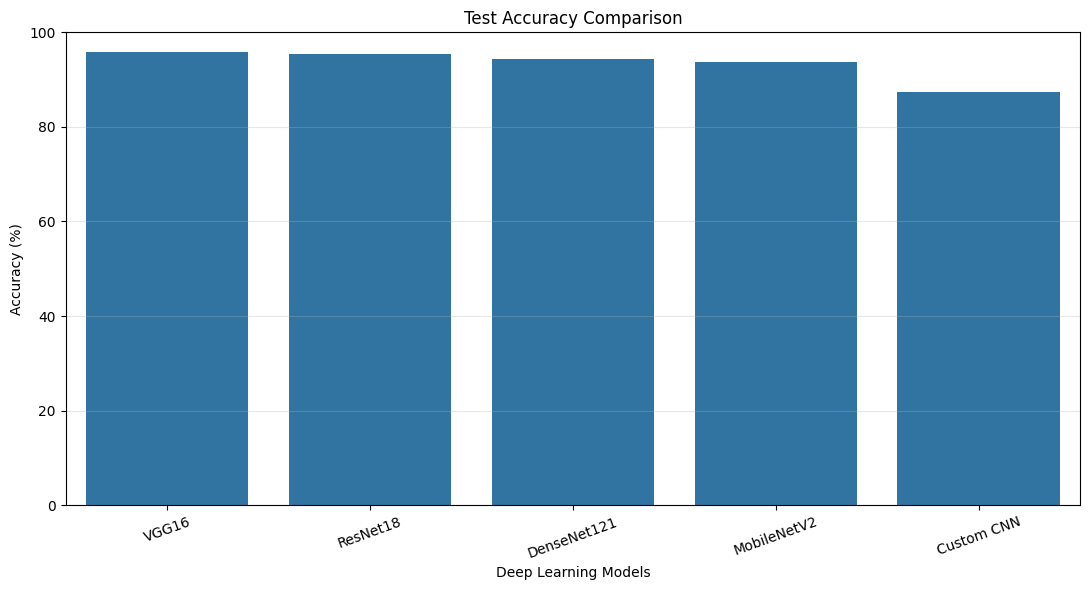

In [62]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=model_comparison.sort_values(
        "Test Accuracy",
        ascending=False
    ),
    x="Model",
    y="Test Accuracy"
)

plt.title("Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Deep Learning Models")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

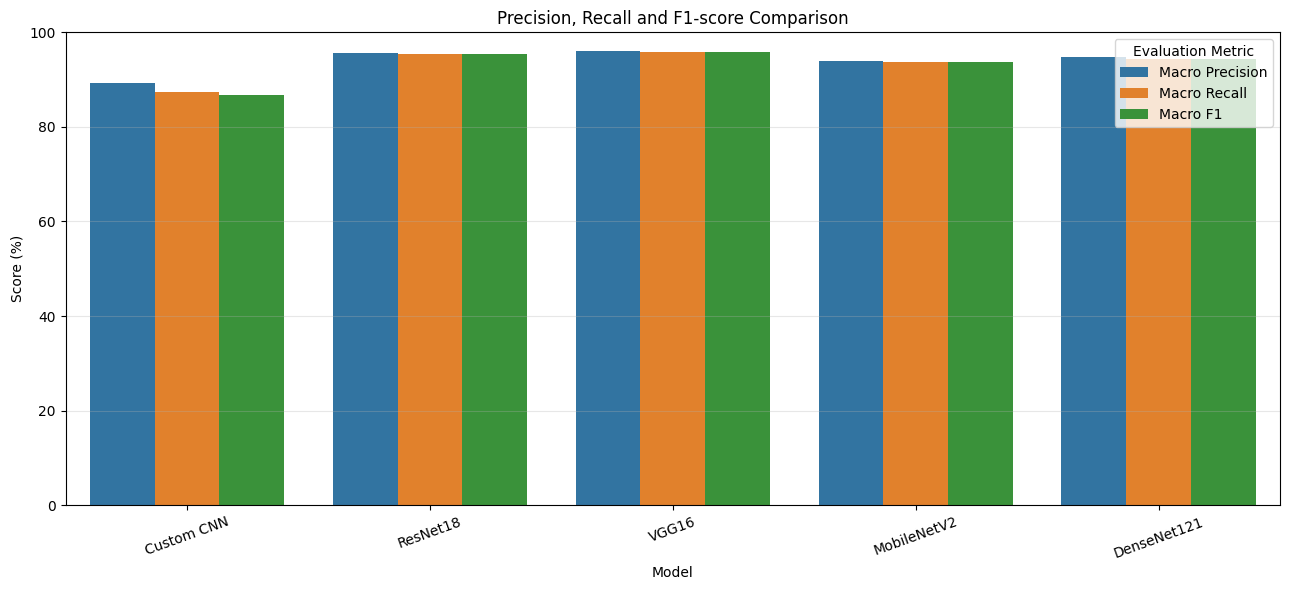

In [63]:
metrics = [
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

comparison_melted = model_comparison.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=comparison_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1-score Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

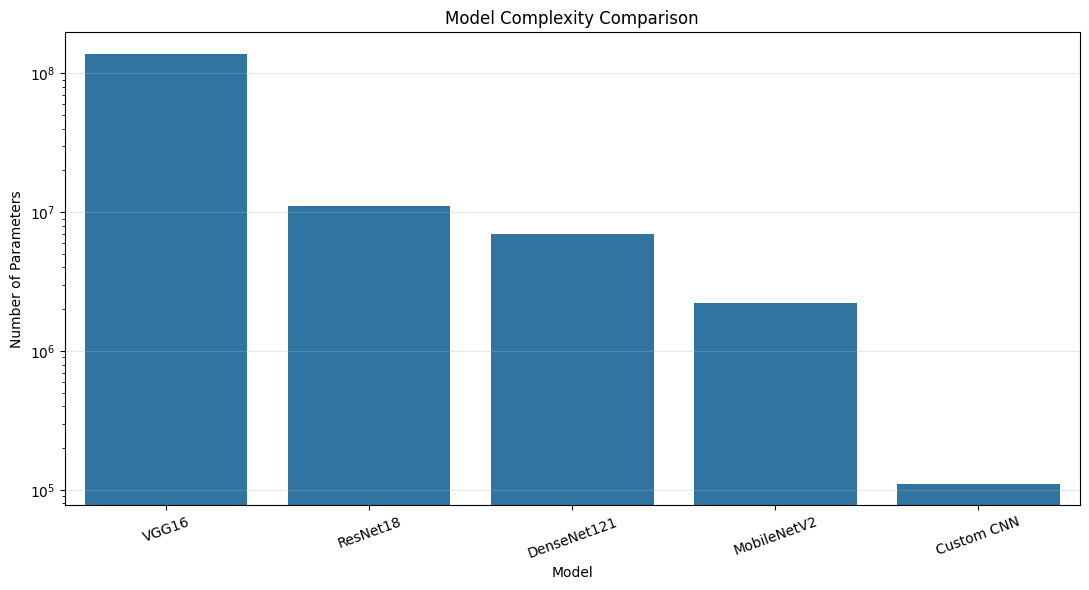

In [64]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=model_comparison.sort_values(
        "Parameters",
        ascending=False
    ),
    x="Model",
    y="Parameters"
)

plt.title("Model Complexity Comparison")
plt.ylabel("Number of Parameters")
plt.xlabel("Model")
plt.yscale("log")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

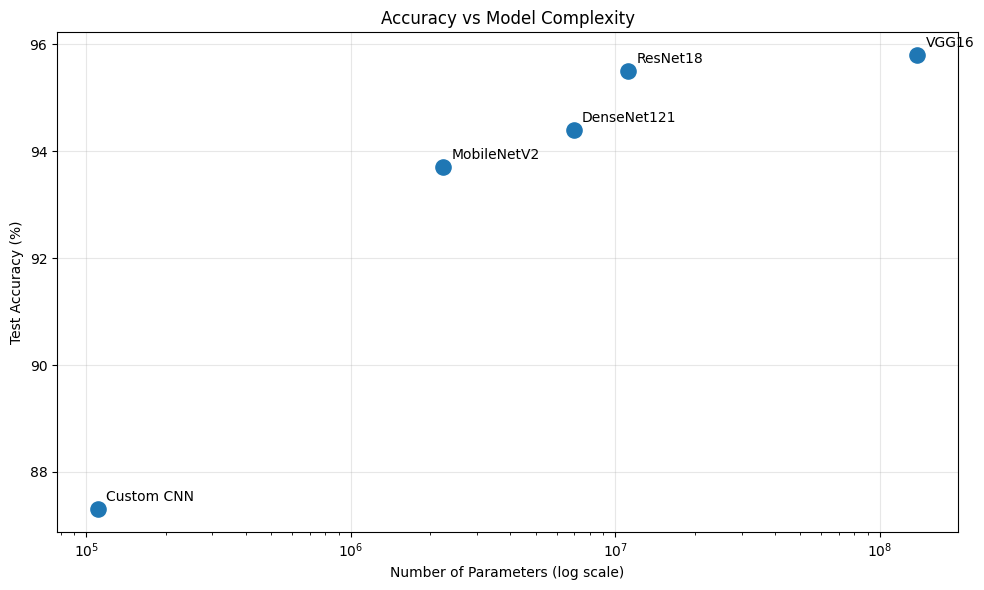

In [65]:
plt.figure(figsize=(10, 6))

plt.scatter(
    model_comparison["Parameters"],
    model_comparison["Test Accuracy"],
    s=120
)

for _, row in model_comparison.iterrows():
    plt.annotate(
        row["Model"],
        (
            row["Parameters"],
            row["Test Accuracy"]
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.title("Accuracy vs Model Complexity")
plt.xlabel("Number of Parameters (log scale)")
plt.ylabel("Test Accuracy (%)")
plt.xscale("log")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()